In [1]:
# Uncomment and run this cell if you're on Colab or Kaggle
!git clone https://github.com/nlp-with-transformers/notebooks.git
%cd notebooks
from install import *
install_requirements()

Cloning into 'notebooks'...
remote: Enumerating objects: 542, done.
remote: Counting objects: 100% (253/253), done.
remote: Compressing objects: 100% (59/59), done.
remote: Total 542 (delta 219), reused 196 (delta 194), pack-reused 289 (from 1)
Receiving objects: 100% (542/542), 34.59 MiB | 10.71 MiB/s, done.
Resolving deltas: 100% (259/259), done.
/content/notebooks
⏳ Installing base requirements ...


Exception: 😭 Failed to install base requirements

In [3]:
%cat requirements.txt

# Base requirements
transformers[torch,sentencepiece,vision,optuna,sklearn,onnxruntime]==4.16.2
datasets[audio]==1.16.1
matplotlib
ipywidgets
# Transitive pins required so the above still install and run on Python 3.10+.
# Without these, current pyarrow (>=14) drops PyExtensionType (breaks datasets 1.16.1),
# current huggingface_hub (>=0.11) drops the cached_download API used by transformers
# 4.16.2, and numpy 2.x is ABI-incompatible with pyarrow 13.
pyarrow<14
huggingface_hub<0.11
numpy<1.24
tokenizers<0.12
pandas<2
protobuf<3.21 # newer protobuf breaks the sentencepiece/pegasus _pb2.py files transformers 4.16.2 ships
# Chapter 2 - Classification
umap-learn==0.5.1
# Chapter 3 - Anatomy
bertviz==1.2.0
# Chapter 4 - NER
seqeval==1.2.2
# Chapter 6 - Summarization
nltk==3.8.1 # 3.9 has a WordNetLemmatizer bug that loads wordnet at import time
sacrebleu==1.5.1
rouge-score==0.0.4
py7zr<0.20 # Needed for samsum dataset (newer versions removed SevenZipFile.readall used by the loader)
# Chapt

In [4]:
!pip install transformers datasets accelerate

In [6]:
# 1. Klargjort installationscelle (kør denne, hvis du starter en ny session)
!pip install transformers datasets accelerate

In [7]:
# 2. Testcelle for at bekræfte installationen
try:
    import transformers
    import datasets
    import accelerate
    print("✅ Succes! Alle biblioteker er korrekt installeret og klar til brug.")
except ImportError as e:
    print(f"❌ Fejl: {e}. Prøv at køre installationscellen ovenfor igen.")

✅ Succes! Alle biblioteker er korrekt installeret og klar til brug.


In [8]:
#hide
from utils import *
setup_chapter()

No GPU was detected! This notebook can be *very* slow without a GPU 🐢
Go to Runtime > Change runtime type and select a GPU hardware accelerator.
Using transformers v5.22.1
Using datasets v4.8.5


# Hello Transformers

<img alt="transformer-timeline" caption="The transformers timeline" src="https://github.com/nlp-with-transformers/notebooks/blob/main/images/chapter01_timeline.png?raw=1" id="transformer-timeline"/>

## The Encoder-Decoder Framework

<img alt="rnn" caption="Unrolling an RNN in time." src="https://github.com/nlp-with-transformers/notebooks/blob/main/images/chapter01_rnn.png?raw=1" id="rnn"/>

<img alt="enc-dec" caption="Encoder-decoder architecture with a pair of RNNs. In general, there are many more recurrent layers than those shown." src="https://github.com/nlp-with-transformers/notebooks/blob/main/images/chapter01_enc-dec.png?raw=1" id="enc-dec"/>

## Attention Mechanisms

<img alt="enc-dec-attn" caption="Encoder-decoder architecture with an attention mechanism for a pair of RNNs." src="https://github.com/nlp-with-transformers/notebooks/blob/main/images/chapter01_enc-dec-attn.png?raw=1" id="enc-dec-attn"/>

<img alt="attention-alignment" width="500" caption="RNN encoder-decoder alignment of words in English and the generated translation in French (courtesy of Dzmitry Bahdanau)." src="https://github.com/nlp-with-transformers/notebooks/blob/main/images/chapter02_attention-alignment.png?raw=1" id="attention-alignment"/>

<img alt="transformer-self-attn" caption="Encoder-decoder architecture of the original Transformer." src="https://github.com/nlp-with-transformers/notebooks/blob/main/images/chapter01_self-attention.png?raw=1" id="transformer-self-attn"/>

## Transfer Learning in NLP

<img alt="transfer-learning" caption="Comparison of traditional supervised learning (left) and transfer learning (right)." src="https://github.com/nlp-with-transformers/notebooks/blob/main/images/chapter01_transfer-learning.png?raw=1" id="transfer-learning"/>  

<img alt="ulmfit" width="500" caption="The ULMFiT process (courtesy of Jeremy Howard)." src="https://github.com/nlp-with-transformers/notebooks/blob/main/images/chapter01_ulmfit.png?raw=1" id="ulmfit"/>

## Hugging Face Transformers: Bridging the Gap

## A Tour of Transformer Applications

In [10]:
text = """Dear Amazon, last week I ordered an Optimus Prime action figure \
from your online store in Germany. Unfortunately, when I opened the package, \
I discovered to my horror that I had been sent an action figure of Megatron \
instead! As a lifelong enemy of the Decepticons, I hope you can understand my \
dilemma. To resolve the issue, I demand an exchange of Megatron for the \
Optimus Prime figure I ordered. Enclosed are copies of my records concerning \
this purchase. I expect to hear from you soon. Sincerely, Bumblebee."""

### Text Classification

In [11]:
#hide_output
from transformers import pipeline

classifier = pipeline("text-classification")

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

In [13]:
import pandas as pd

outputs = classifier(text)
pd.DataFrame(outputs)

,label,score
0,NEGATIVE,0.901546


### Named Entity Recognition

In [ ]:
ner_tagger = pipeline("ner", aggregation_strategy="simple")
outputs = ner_tagger(text)
pd.DataFrame(outputs)

,entity_group,score,word,start,end
0,ORG,0.879010,Amazon,5,11
1,MISC,0.990859,Optimus Prime,36,49
2,LOC,0.999755,Germany,90,97
3,MISC,0.556569,Mega,208,212
4,PER,0.590256,##tron,212,216
5,ORG,0.669692,Decept,253,259
6,MISC,0.498350,##icons,259,264
7,MISC,0.775361,Megatron,350,358
8,MISC,0.987854,Optimus Prime,367,380
9,PER,0.812096,Bumblebee,502,511


### Question Answering

In [ ]:
reader = pipeline("question-answering")
question = "What does the customer want?"
outputs = reader(question=question, context=text)
pd.DataFrame([outputs])

,score,start,end,answer
0,0.631291,335,358,an exchange of Megatron


### Summarization

In [ ]:
summarizer = pipeline("summarization")
outputs = summarizer(text, max_length=45, clean_up_tokenization_spaces=True)
print(outputs[0]['summary_text'])

 Bumblebee ordered an Optimus Prime action figure from your online store in
Germany. Unfortunately, when I opened the package, I discovered to my horror
that I had been sent an action figure of Megatron instead.


### Translation

In [ ]:
translator = pipeline("translation_en_to_de",
                      model="Helsinki-NLP/opus-mt-en-de")
outputs = translator(text, clean_up_tokenization_spaces=True, min_length=100)
print(outputs[0]['translation_text'])

Sehr geehrter Amazon, letzte Woche habe ich eine Optimus Prime Action Figur aus
Ihrem Online-Shop in Deutschland bestellt. Leider, als ich das Paket öffnete,
entdeckte ich zu meinem Entsetzen, dass ich stattdessen eine Action Figur von
Megatron geschickt worden war! Als lebenslanger Feind der Decepticons, Ich
hoffe, Sie können mein Dilemma verstehen. Um das Problem zu lösen, Ich fordere
einen Austausch von Megatron für die Optimus Prime Figur habe ich bestellt.
Anbei sind Kopien meiner Aufzeichnungen über diesen Kauf. Ich erwarte, bald von
Ihnen zu hören. Aufrichtig, Bumblebee.


### Text Generation

In [ ]:
#hide
from transformers import set_seed
set_seed(42) # Set the seed to get reproducible results

In [ ]:
generator = pipeline("text-generation")
response = "Dear Bumblebee, I am sorry to hear that your order was mixed up."
prompt = text + "\n\nCustomer service response:\n" + response
outputs = generator(prompt, max_length=200)
print(outputs[0]['generated_text'])

Dear Amazon, last week I ordered an Optimus Prime action figure from your online
store in Germany. Unfortunately, when I opened the package, I discovered to my
horror that I had been sent an action figure of Megatron instead! As a lifelong
enemy of the Decepticons, I hope you can understand my dilemma. To resolve the
issue, I demand an exchange of Megatron for the Optimus Prime figure I ordered.
Enclosed are copies of my records concerning this purchase. I expect to hear
from you soon. Sincerely, Bumblebee.

Customer service response:
Dear Bumblebee, I am sorry to hear that your order was mixed up. The order was
completely mislabeled, which is very common in our online store, but I can
appreciate it because it was my understanding from this site and our customer
service of the previous day that your order was not made correct in our mind and
that we are in a process of resolving this matter. We can assure you that your
order


In [1]:
import pandas as pd

# 1. Vi opretter nogle simple data (f.eks. feedback-analyse af produkter)
data = {
    'Produkt': ['Optimus Prime', 'Megatron', 'Bumblebee', 'Barricade', 'Starscream'],
    'Positive_Anmeldelser': [85, 42, 95, 30, 55],
    'Negative_Anmeldelser': [15, 58, 5, 70, 45]
}

# 2. Vi laver det om til en pæn pandas tabel (DataFrame)
df = pd.DataFrame(data)

# 3. Vi tilføjer en brugbar beregning: den samlede positive procentdel
df['Positiv_Andel_Pct'] = (df['Positive_Anmeldelser'] / (df['Positive_Anmeldelser'] + df['Negative_Anmeldelser'])) * 100

# Vi viser tabellen pænt i Colab
display(df)

,Produkt,Positive_Anmeldelser,Negative_Anmeldelser,Positiv_Andel_Pct
0,Optimus Prime,85,15,85.0
1,Megatron,42,58,42.0
2,Bumblebee,95,5,95.0
3,Barricade,30,70,30.0
4,Starscream,55,45,55.0


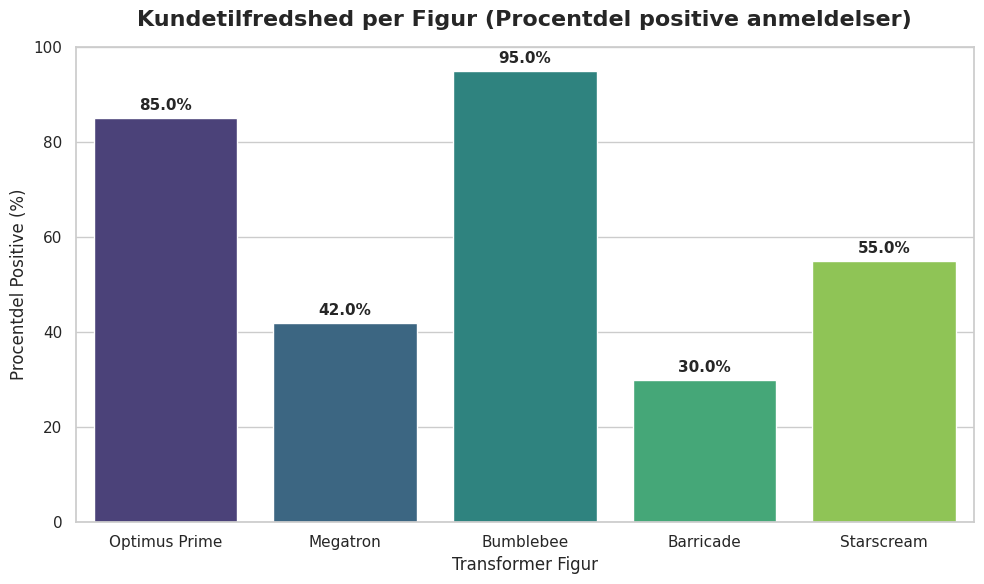

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# Vi sætter stilen til at være pæn og moderne
sns.set_theme(style="whitegrid")

# Vi opretter en figur med en god størrelse
plt.figure(figsize=(10, 6))

# Vi laver en barplot (søjlediagram) over den positive andel for hvert produkt
ax = sns.barplot(x='Produkt', y='Positiv_Andel_Pct', data=df, palette='viridis', hue='Produkt', legend=False)

# Vi tilføjer titler og labels så det er nemt at forstå
plt.title('Kundetilfredshed per Figur (Procentdel positive anmeldelser)', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Transformer Figur', fontsize=12)
plt.ylabel('Procentdel Positive (%)', fontsize=12)
plt.ylim(0, 100) # Sætter y-aksen fra 0 til 100%

# Vi tilføjer tal-værdier ovenpå hver søjle, så grafen er super nem at aflæse
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 9),
                textcoords='offset points',
                fontsize=11, fontweight='bold')

# Viser grafen lige herunder
plt.tight_layout()
plt.show()

### 📊 Avanceret Dashboard & Visuel Datapræsentation
Herunder opretter vi en visuelt formateret tabel og et dobbelt-diagram (subplots) for at give en langt dybere og mere professionel indsigt i vores data.

STYLISH DATAFRAME:


,Produkt,Positive_Anmeldelser,Negative_Anmeldelser,Positiv_Andel_Pct
0,Optimus Prime,85,15,85.0%
1,Megatron,42,58,42.0%
2,Bumblebee,95,5,95.0%
3,Barricade,30,70,30.0%
4,Starscream,55,45,55.0%


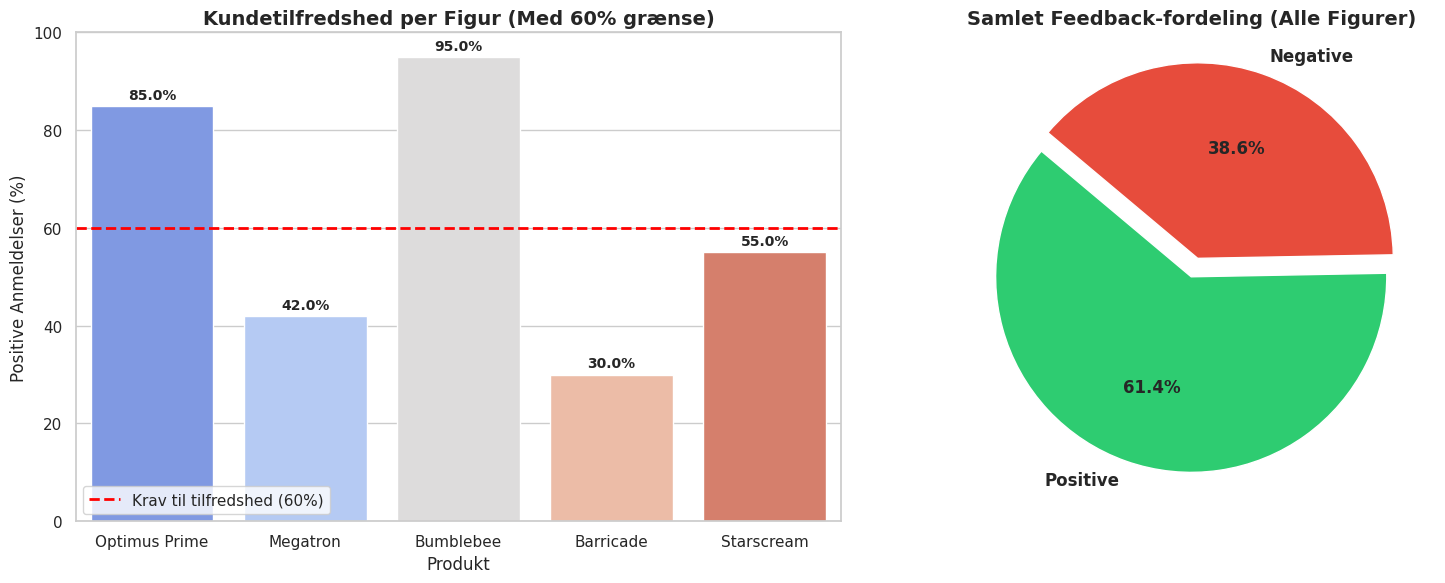

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# --- 1. FARVEKODET TABEL (PANDAS STYLING) ---
# Vi bruger en farveskala (colormap) så høje positive procenter automatisk lyser grønt op
styled_df = df.style.background_gradient(cmap='RdYlGn', subset=['Positiv_Andel_Pct']) \
                    .format({'Positiv_Andel_Pct': '{:.1f}%'}) \
                    .highlight_max(subset=['Positive_Anmeldelser'], color='lightgreen') \
                    .highlight_min(subset=['Negative_Anmeldelser'], color='lightgreen')

print("STYLISH DATAFRAME:")
display(styled_df)

# --- 2. MULTI-PANEL GRAF (SUBPLOTS) ---
# Vi opretter et lærred med 1 række og 2 kolonner af grafer
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# FIGUR 1: Søjlediagram med en tærskel-linje
sns.barplot(ax=axes[0], x='Produkt', y='Positiv_Andel_Pct', data=df, palette='coolwarm', hue='Produkt', legend=False)
axes[0].axhline(60, color='red', linestyle='--', linewidth=2, label='Krav til tilfredshed (60%)') # Advarselslinje
axes[0].set_title('Kundetilfredshed per Figur (Med 60% grænse)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Positive Anmeldelser (%)')
axes[0].set_ylim(0, 100)
axes[0].legend(loc='lower left')

# Tilføj procenter på søjlerne
for p in axes[0].patches:
    if p.get_height() > 0: # Undgå fejl hvis en søjle er tom
        axes[0].annotate(f"{p.get_height():.1f}%",
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center',
                    xytext=(0, 8),
                    textcoords='offset points',
                    fontsize=10, fontweight='bold')

# FIGUR 2: Lagkagediagram over den samlede feedback på tværs af alle produkter
total_positive = df['Positive_Anmeldelser'].sum()
total_negative = df['Negative_Anmeldelser'].sum()

axes[1].pie(
    [total_positive, total_negative],
    labels=['Positive', 'Negative'],
    autopct='%1.1f%%',
    startangle=140,
    colors=['#2ecc71', '#e74c3c'],
    explode=(0, 0.1), # Gør det negative stykke lidt fritlagt for effekt
    textprops={'fontsize': 12, 'fontweight': 'bold'}
)
axes[1].set_title('Samlet Feedback-fordeling (Alle Figurer)', fontsize=14, fontweight='bold')

# Vis den samlede dashboard-figur
plt.tight_layout()
plt.show()

### 🌐 Interaktivt Økonomi-Dashboard (Gradio Web App)
Herunder installerer og opbygger vi en fuldt interaktiv webside direkte i din notebook, som præsenterer en virksomheds økonomiske nøgletal (omsætning, profit, udgifter) i et moderne og stilrent design.

In [5]:
# Først installerer vi Gradio, som laver koden om til en flot webside
!pip install -q gradio

import gradio as gr
import pandas as pd
import plotly.graph_objects as go

# 1. Vi definerer virksomhedens data og formaterer tal med tusindtals-punktum
oekonomi_data = {
    'Kvartal': ['Q1', 'Q2', 'Q3', 'Q4'],
    'Omsætning': [1200000, 1500000, 1800000, 2300000],
    'Udgifter': [800000, 950000, 1100000, 1200000],
}
df_finance = pd.DataFrame(oekonomi_data)
df_finance['Profit'] = df_finance['Omsætning'] - df_finance['Udgifter']
df_finance['Profit_Margen_%'] = (df_finance['Profit'] / df_finance['Omsætning']) * 100

# Funktion til pæn formatering af danske kroner i tabellen
def formater_danske_kroner(val):
    return f"{val:,.0f}".replace(",", ".")

# Opret en pænt formateret kopi af tabellen til visning
df_visning = df_finance.copy()
df_visning['Omsætning'] = df_visning['Omsætning'].map(formater_danske_kroner)
df_visning['Udgifter'] = df_visning['Udgifter'].map(formater_danske_kroner)
df_visning['Profit'] = df_visning['Profit'].map(formater_danske_kroner)
df_visning['Profit_Margen_%'] = df_visning['Profit_Margen_%'].map(lambda x: f"{x:.1f}%")

# Hjælpefunktion til at formatere KPI-værdier med punktum til Gradio
def format_kpi(tal):
    return f"{tal:,.0f}".replace(",", ".")

# 2. Funktion der genererer graferne
def opdater_dashboard(visning_type):
    if visning_type == "Omsætning vs. Udgifter":
        fig = go.Figure()
        fig.add_trace(go.Bar(x=df_finance['Kvartal'], y=df_finance['Omsætning'], name='Omsætning', marker_color='#2ecc71'))
        fig.add_trace(go.Bar(x=df_finance['Kvartal'], y=df_finance['Udgifter'], name='Udgifter', marker_color='#e74c3c'))
        fig.update_layout(title='Omsætning vs. Udgifter (2024)', barmode='group', template='plotly_dark')
    else:
        fig = go.Figure()
        fig.add_trace(go.Scatter(x=df_finance['Kvartal'], y=df_finance['Profit'], name='Netto Profit', line=dict(color='#2ecc71', width=4), mode='lines+markers'))
        fig.update_layout(title='Netto Profit Udvikling', template='plotly_dark')

    fig.update_layout(
        paper_bgcolor='rgba(0,0,0,0)',
        plot_bgcolor='rgba(0,0,0,0)',
        font=dict(color='white')
    )
    return df_visning, fig

# 3. Custom CSS til Mat-grøn Stained Glass (frosted glass) og LEGO-dots
custom_css = """
/* Styling af KPI kortene til mat-grøn med stained glass (frosted glass) effekt */
.lego-card {
    background: rgba(46, 204, 113, 0.15) !important; /* Mat-grøn med gennemsigtighed */
    backdrop-filter: blur(12px) !important; /* Stained-glass / frosted effekt */
    border: 2px solid rgba(46, 204, 113, 0.3) !important;
    border-radius: 12px !important;
    padding: 20px !important;
    position: relative !important;
    box-shadow: 0 8px 32px 0 rgba(0, 0, 0, 0.37) !important;
    margin-top: 20px !important;
}

/* LEGO-dots på toppen af kortene */
.lego-card::before {
    content: '';
    position: absolute;
    top: -10px;
    left: 10%;
    right: 10%;
    height: 10px;
    /* Dette genererer en række af små 3D lego-knopper */
    background-image: radial-gradient(
        circle,
        rgba(46, 204, 113, 0.6) 0%,
        rgba(39, 174, 96, 0.8) 40%,
        rgba(0, 0, 0, 0.4) 80%,
        transparent 100%
    );
    background-size: 24px 10px;
    background-repeat: repeat-x;
    border-radius: 4px 4px 0 0;
}
"""

# 4. Vi designer web-interfacet
with gr.Blocks(css=custom_css) as demo:
    gr.Markdown("""
    # 🧱 Det Grønne LEGO® Finans-Cockpit
    Velkommen til din opdaterede og fuldt tilpassede browserside med specialdesignede matte glas-paneler.
    """)

    with gr.Row():
        # Hurtige KPI-kort indpakket i vores nye LEGO 'lego-card' CSS-klasse
        with gr.Column(elem_classes="lego-card"):
            gr.Label(value=f"{format_kpi(sum(df_finance['Omsætning']))} DKK", label="Samlet Omsætning")
        with gr.Column(elem_classes="lego-card"):
            gr.Label(value=f"{format_kpi(sum(df_finance['Profit']))} DKK", label="Samlet Profit")
        with gr.Column(elem_classes="lego-card"):
            gr.Label(value=f"{df_finance['Profit_Margen_%'].mean():.1f}%", label="Gns. Profitmargin")

    with gr.Row():
        with gr.Column(scale=1):
            gr.Markdown("### Indstillinger")
            valg = gr.Radio(["Omsætning vs. Udgifter", "Profit-udvikling"], label="Vælg Graf-visning", value="Omsætning vs. Udgifter")

        with gr.Column(scale=3):
            tabel_output = gr.Dataframe(label="Formateret Finansiel Rapport")
            graf_output = gr.Plot(label="Interaktiv Graf")

    # Forbind elementerne
    valg.change(fn=opdater_dashboard, inputs=valg, outputs=[tabel_output, graf_output])
    demo.load(fn=opdater_dashboard, inputs=valg, outputs=[tabel_output, graf_output])

# Start appen
demo.launch(inline=True, show_error=True)

/tmp/ipykernel_1928/2845955506.py:89: UserWarning:

The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: css. Please pass these parameters to launch() instead.



It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://57a86154597530ffa9.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## The Hugging Face Ecosystem

<img alt="ecosystem" width="500" caption="An overview of the Hugging Face ecosystem of libraries and the Hub." src="https://github.com/nlp-with-transformers/notebooks/blob/main/images/chapter01_hf-ecosystem.png?raw=1" id="ecosystem"/>

### The Hugging Face Hub

<img alt="hub-overview" width="1000" caption="The models page of the Hugging Face Hub, showing filters on the left and a list of models on the right." src="https://github.com/nlp-with-transformers/notebooks/blob/main/images/chapter01_hub-overview.png?raw=1" id="hub-overview"/>

<img alt="hub-model-card" width="1000" caption="A example model card from the Hugging Face Hub. The inference widget is shown on the right, where you can interact with the model." src="https://github.com/nlp-with-transformers/notebooks/blob/main/images/chapter01_hub-model-card.png?raw=1" id="hub-model-card"/>

### Hugging Face Tokenizers

### Hugging Face Datasets

### Hugging Face Accelerate

## Main Challenges with Transformers

## Conclusion